# Chapitre 7 - Cours 1 : ACID, atomicité et durabilité

Ce notebook couvre la première grande section du chapitre, *The Slippery Concept of a
Transaction* : l'introduction du chapitre, *The Meaning of ACID* (*Atomicity*,
*Consistency*, *Isolation*, *Durability*, l'encadré *Replication and Durability*) et
*Single-Object and Multi-Object Operations* (*Single-object writes*, *The need for
multi-object transactions*, *Handling errors and aborts*). Les niveaux d'isolation sont
l'objet des cours 2 à 4 ; la validation atomique distribuée (2PC) sera traitée au
chapitre 9.

**Plan.**

1. Pourquoi des transactions ? Ce qui peut mal tourner.
2. ACID lettre par lettre (et pourquoi le « C » est à part).
3. Atomicité : un journal pour faire « tout ou rien ».
4. Durabilité : fsync, validation groupée et réplication.
5. Opérations sur un objet, opérations sur plusieurs objets.
6. Abandonner et réessayer : une bonne idée, avec des limites.

Le livre ne contient ni code ni exercices : tout ce qui est implémenté ici l'est « à la
main », dans le module [`ddia/transactions.py`](../../ddia/transactions.py).

In [1]:
import os
import sqlite3
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from ddia import transactions as tr
from ddia.transactions import R, W, run, plot_history
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
# graduations des axes logarithmiques sans mathtext (la police du style n'a pas le signe moins)
LOGFMT = FuncFormatter(lambda v, _: f"{v:g}")
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Pourquoi des transactions ? (introduction du chapitre)

Une application qui stocke des données doit survivre à une longue liste de mésaventures :
la base ou la machine peut tomber **au milieu d'une écriture**, l'application peut planter
**entre deux opérations**, le réseau peut couper l'application de la base, plusieurs
clients peuvent écrire **en même temps** et s'écraser mutuellement, un client peut lire
des données **à moitié mises à jour**, et les **conditions de course** entre clients
produisent des bogues déroutants.

Traiter chacun de ces cas dans le code applicatif est long et fragile. La **transaction**
regroupe plusieurs lectures et écritures en une unité logique : soit tout est validé
(*commit*), soit tout est annulé (*abort*, *rollback*), et l'application peut alors
réessayer sans crainte. C'est une **abstraction** : la base prend en charge certaines
pannes et certains problèmes de concurrence pour que l'application puisse les ignorer
(ce sont des **garanties de sûreté**).

Le schéma situe les points de défaillance que la transaction neutralise.

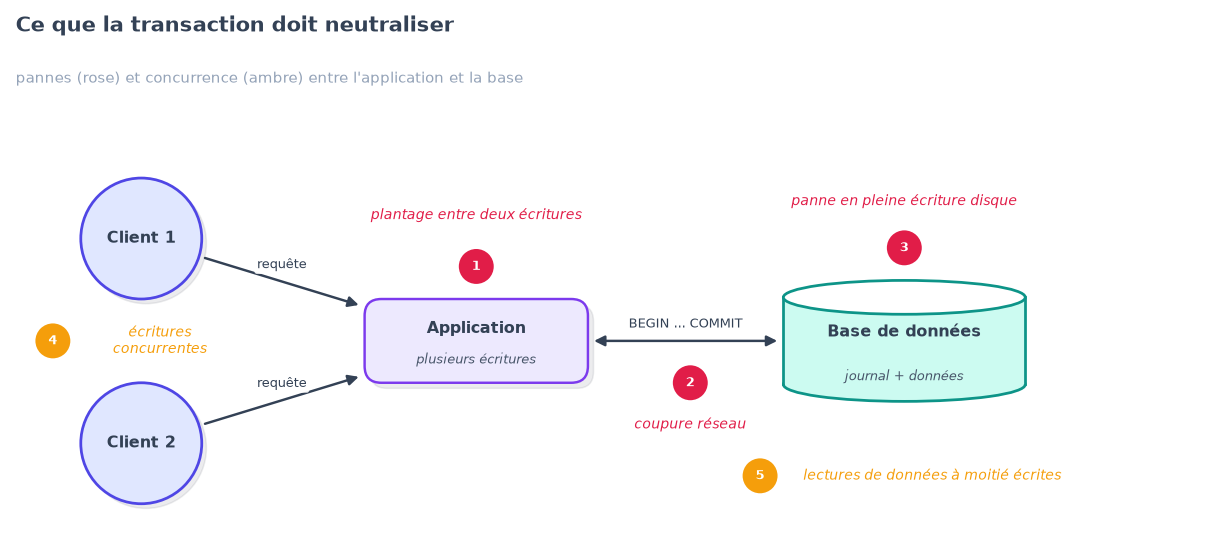

In [2]:
d = Diagram(13, 4.6, title="Ce que la transaction doit neutraliser",
            subtitle="pannes (rose) et concurrence (ambre) entre l'application et la base")
d.box("c1", 1.4, 3.1, "Client 1", kind="user", w=1.3, color=INDIGO)
d.box("c2", 1.4, 0.9, "Client 2", kind="user", w=1.3, color=INDIGO)
d.box("app", 5.0, 2.0, "Application", sub="plusieurs écritures", color=VIOLET, w=2.4)
d.box("db", 9.6, 2.0, "Base de données", sub="journal + données", color=TEAL, kind="db", w=2.6, h=1.3)
d.arrow("c1", "app", "requête")
d.arrow("c2", "app", "requête")
d.arrow("app", "db", "BEGIN ... COMMIT", both=True)
d.badge(5.0, 2.8, "1", color=ROSE)
d.note(5.0, 3.35, "plantage entre deux écritures", color=ROSE)
d.badge(7.3, 1.55, "2", color=ROSE)
d.note(7.3, 1.1, "coupure réseau", color=ROSE)
d.badge(9.6, 3.0, "3", color=ROSE)
d.note(9.6, 3.5, "panne en pleine écriture disque", color=ROSE)
d.badge(0.45, 2.0, "4", color=AMBER)
d.note(1.6, 2.0, "écritures\nconcurrentes", color=AMBER)
d.badge(8.05, 0.55, "5", color=AMBER)
d.note(9.9, 0.55, "lectures de données à moitié écrites", color=AMBER)
d.show()

Les transactions ne sont pas une loi de la nature : elles ont été conçues (System R
d'IBM, 1975) pour **simplifier le modèle de programmation**. Toutes les bases
relationnelles en ont hérité presque à l'identique. À la fin des années 2000, la vague
NoSQL en a souvent fait la première victime (abandon pur et simple, ou mot redéfini pour
désigner des garanties bien plus faibles), d'où l'idée répandue que les transactions
« ne passent pas à l'échelle ».

> **À retenir.** Une transaction transforme une multitude de scénarios d'erreur
> (pannes partielles, concurrence) en un seul : « la transaction a échoué, on peut la
> réessayer ». C'est une abstraction qui a un coût : il faut savoir ce qu'elle garantit
> vraiment, et à quel prix.

## 2. ACID lettre par lettre (section *The Meaning of ACID*)

L'acronyme (Härder et Reuter, 1983) désigne **A**tomicité, **C**ohérence, **I**solation,
**D**urabilité. Le livre prévient : en pratique, l'ACID d'une base n'est pas celui d'une
autre, et le mot est devenu en partie un argument commercial. Son contraire marketing,
BASE (*basically available, soft state, eventual consistency*), est encore plus flou.

| lettre | idée | ce qui se passe sans | qui la garantit |
|---|---|---|---|
| **A**tomicité | une transaction interrompue est **annulée** entièrement : on pourrait dire « abandonnabilité » | écritures partielles, on ne sait pas quoi refaire | la base (journal) |
| **C**ohérence | les **invariants** de l'application restent vrais d'une validation à l'autre | soldes faux, références cassées | surtout l'application (la base n'aide que via les contraintes déclarées) |
| **I**solation | les transactions concurrentes ne se marchent pas dessus ; idéalement **sérialisabilité** | conditions de course | la base (contrôle de concurrence) |
| **D**urabilité | une transaction validée **n'est pas oubliée** | données perdues après une panne | la base (disque, réplication) ; jamais absolue |

Deux pièges de vocabulaire :

- l'**atomicité** ACID n'a rien à voir avec la concurrence (contrairement à une
  opération atomique en programmation multithread) : elle parle de **pannes** ;
- le mot **cohérence** a au moins cinq sens dans le livre : cohérence des répliques
  (chapitre 5), instantané cohérent, hachage cohérent
  (chapitre 6), cohérence au sens CAP, c'est-à-dire linéarisabilité
  (chapitre 9), et cohérence ACID (invariants). Le « C » est une propriété
  de l'application, pas de la base : il dépend de A, I et D, mais aussi de la justesse
  du code.

**L'isolation en une expérience.** Deux clients incrémentent un compteur qui vaut 42 :
chacun lit, ajoute 1, réécrit. Sans isolation suffisante, on obtient 43 au lieu de 44.
Rejouons-le avec le mini-moteur du module : chaque transaction est un **générateur**
Python qui produit des opérations (`R` lecture, `W` écriture) ; l'ordonnanceur les
entrelace selon l'ordre imposé `"ABAB..."`.

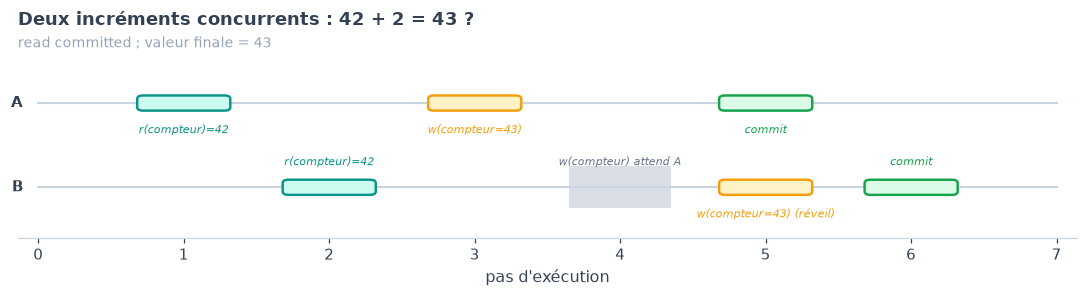

,pas,tx,op,type
0,1,A,r(compteur)=42,read
1,2,B,r(compteur)=42,read
2,3,A,w(compteur=43),write
3,4,B,w(compteur) attend A,wait
4,5,A,commit,commit
5,5,B,w(compteur=43),write
6,6,B,commit,commit


In [3]:
def incremente(cle):
    def prog():
        v = yield R(cle)
        yield W(cle, v + 1)
    return prog


res = run({"compteur": 42}, {"A": incremente("compteur"), "B": incremente("compteur")},
          "ABABAB", level="read_committed")
st = plot_history(res, title="Deux incréments concurrents : 42 + 2 = 43 ?",
                  subtitle=f"read committed ; valeur finale = {res.final['compteur']}", width=10)
st.show()
res.history[["pas", "tx", "op", "type"]]

Chaque ligne est une transaction, chaque colonne un pas d'exécution : lectures en
sarcelle, écritures en ambre, validation en vert, attente de verrou en gris. B lit 42
avant que A n'ait écrit ; son écriture (qui doit attendre que A valide, car A détient le
verrou d'écriture) écrase donc celle de A : c'est la **mise à jour perdue**, que l'on
étudiera au cours 3. En série (A puis B), on aurait 44.

> **À retenir.** A = abandon sûr en cas de panne, C = invariants de l'application,
> I = pas d'interférence entre transactions concurrentes, D = pas d'oubli après
> validation. A, I et D sont des propriétés de la base ; C est surtout l'affaire de
> l'application.